In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display all columns
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Create a sample e-commerce sales dataset

import numpy as np
import pandas as pd

# Generate random data
rng = np.random.default_rng(42)

n = 2000

orders = pd.DataFrame({

    "order_date": pd.to_datetime("2025-01-01") +
    pd.to_timedelta(rng.integers(0, 365, n), unit="D"),

    "customer_id": rng.integers(1, 301, n),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n,
        p=[0.30, 0.35, 0.20, 0.15]
    ),

    "amount": rng.gamma(2.0, 600, n).round(2)

})

print("Dataset created successfully!")

Dataset created successfully!


In [3]:
print("FIRST FIVE RECORDS")

print(orders.head())

FIRST FIVE RECORDS
  order_date  customer_id     category   amount
0 2025-02-02          264         Home   391.13
1 2025-10-10           19      Fashion  2456.21
2 2025-08-27          120        Books   674.90
3 2025-06-10          138         Home    75.38
4 2025-06-08          240  Electronics   774.42


In [4]:
# Check dataset information

print("DATASET SHAPE")
print(orders.shape)

print("\nCOLUMN NAMES")
print(orders.columns)

print("\nDATA TYPES")
print(orders.dtypes)

print("\nMISSING VALUES")
print(orders.isnull().sum())

print("\nDUPLICATE ROWS")
print(orders.duplicated().sum())

DATASET SHAPE
(2000, 4)

COLUMN NAMES
Index(['order_date', 'customer_id', 'category', 'amount'], dtype='object')

DATA TYPES
order_date     datetime64[ns]
customer_id             int64
category               object
amount                float64
dtype: object

MISSING VALUES
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

DUPLICATE ROWS
0


In [5]:
# Statistical summary

print("STATISTICAL SUMMARY")

print(orders.describe())

STATISTICAL SUMMARY
                       order_date  customer_id       amount
count                        2000  2000.000000  2000.000000
mean   2025-07-01 22:45:07.200000   151.195500  1202.116645
min           2025-01-01 00:00:00     1.000000     8.810000
25%           2025-03-31 18:00:00    74.000000   597.515000
50%           2025-07-02 00:00:00   149.000000  1005.870000
75%           2025-10-03 00:00:00   226.000000  1613.855000
max           2025-12-31 00:00:00   300.000000  6276.090000
std                           NaN    86.210007   826.961568


In [6]:
# FEATURE ENGINEERING

# Extract month
orders["month"] = orders["order_date"].dt.month

# Extract month name
orders["month_name"] = orders["order_date"].dt.month_name()

# Extract weekday
orders["weekday"] = orders["order_date"].dt.day_name()

# Extract quarter
orders["quarter"] = orders["order_date"].dt.quarter

print("Date features created successfully!")

print(orders.head())

Date features created successfully!
  order_date  customer_id     category   amount  month month_name    weekday  \
0 2025-02-02          264         Home   391.13      2   February     Sunday   
1 2025-10-10           19      Fashion  2456.21     10    October     Friday   
2 2025-08-27          120        Books   674.90      8     August  Wednesday   
3 2025-06-10          138         Home    75.38      6       June    Tuesday   
4 2025-06-08          240  Electronics   774.42      6       June     Sunday   

   quarter  
0        1  
1        4  
2        3  
3        2  
4        2  


In [7]:
# MONTHLY SALES ANALYSIS

# Calculate total monthly revenue
monthly_sales = orders.groupby("month_name")["amount"].sum()

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_sales = monthly_sales.reindex(month_order)

# Display monthly sales
print("MONTHLY SALES")
print(monthly_sales.round(2))

# Find best and worst month
print("\nBEST SALES MONTH:", monthly_sales.idxmax())
print("WORST SALES MONTH:", monthly_sales.idxmin())

MONTHLY SALES
month_name
January      193341.87
February     232027.20
March        206327.14
April        197310.20
May          194090.49
June         221889.83
July         221813.81
August       179783.75
September    180569.95
October      183418.13
November     191512.71
December     202148.21
Name: amount, dtype: float64

BEST SALES MONTH: February
WORST SALES MONTH: August


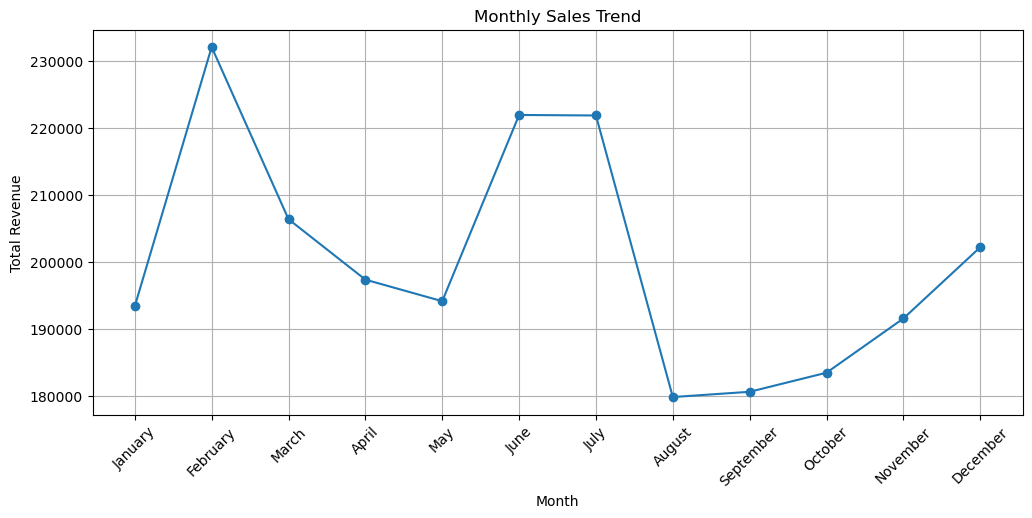

In [8]:
# MONTHLY SALES TREND

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [9]:
# MONTH-OVER-MONTH SALES GROWTH

# Calculate percentage growth
monthly_growth = monthly_sales.pct_change() * 100

# Display monthly growth
print("MONTHLY SALES GROWTH (%)")

print(monthly_growth.round(2))

MONTHLY SALES GROWTH (%)
month_name
January        NaN
February     20.01
March       -11.08
April        -4.37
May          -1.63
June         14.32
July         -0.03
August      -18.95
September     0.44
October       1.58
November      4.41
December      5.55
Name: amount, dtype: float64


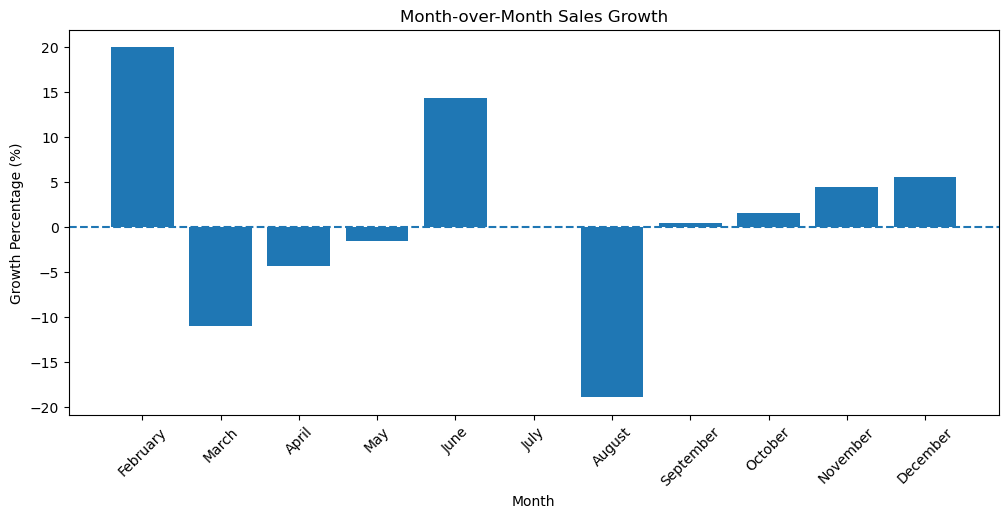

In [10]:
# MONTHLY GROWTH GRAPH

plt.figure(figsize=(12, 5))

plt.bar(
    monthly_growth.index,
    monthly_growth.values
)

plt.title("Month-over-Month Sales Growth")
plt.xlabel("Month")
plt.ylabel("Growth Percentage (%)")

plt.xticks(rotation=45)
plt.axhline(y=0, linestyle="--")

plt.show()

In [11]:
# CATEGORY-WISE SALES ANALYSIS

category_sales = orders.groupby("category")["amount"].agg(
    ["sum", "mean", "count"]
)

# Sort categories by total revenue
category_sales = category_sales.sort_values(
    by="sum",
    ascending=False
)

print("CATEGORY-WISE SALES")
print(category_sales.round(2))

CATEGORY-WISE SALES
                   sum     mean  count
category                              
Fashion      853984.93  1219.98    700
Electronics  722645.53  1163.68    621
Home         464114.66  1218.15    381
Books        363488.17  1219.76    298


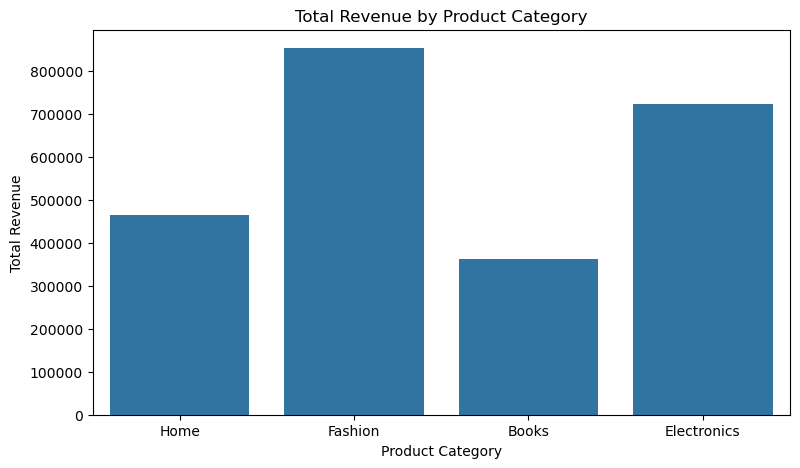

In [12]:
# CATEGORY-WISE REVENUE GRAPH

plt.figure(figsize=(9, 5))

sns.barplot(
    data=orders,
    x="category",
    y="amount",
    estimator=sum,
    errorbar=None
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")

plt.show()

In [13]:
# BEST AND WORST CATEGORY

print("BEST CATEGORY:", category_sales["sum"].idxmax())

print("LOWEST CATEGORY:", category_sales["sum"].idxmin())

BEST CATEGORY: Fashion
LOWEST CATEGORY: Books


In [14]:
# PIVOT TABLE ANALYSIS

pivot_table = pd.pivot_table(
    orders,
    values="amount",
    index="month_name",
    columns="category",
    aggfunc="sum"
)

# Arrange months in calendar order
pivot_table = pivot_table.reindex(month_order)

print("MONTHLY SALES BY CATEGORY")

print(pivot_table.round(2))

MONTHLY SALES BY CATEGORY
category       Books  Electronics   Fashion      Home
month_name                                           
January     29186.89     62841.89  64665.99  36647.10
February    34034.13     53564.89  86123.31  58304.87
March       27843.58     58055.95  75138.67  45288.94
April       26593.72     83335.56  57057.72  30323.20
May         34425.63     57219.16  68569.90  33875.80
June        32936.76     60037.00  85598.09  43317.98
July        35582.36     72649.65  72647.96  40933.84
August      32550.65     56690.46  71251.54  19291.10
September   21824.73     60388.56  60231.75  38124.91
October     23728.54     48799.72  70978.87  39911.00
November    35826.81     51641.63  65122.45  38921.82
December    28954.37     57421.06  76598.68  39174.10


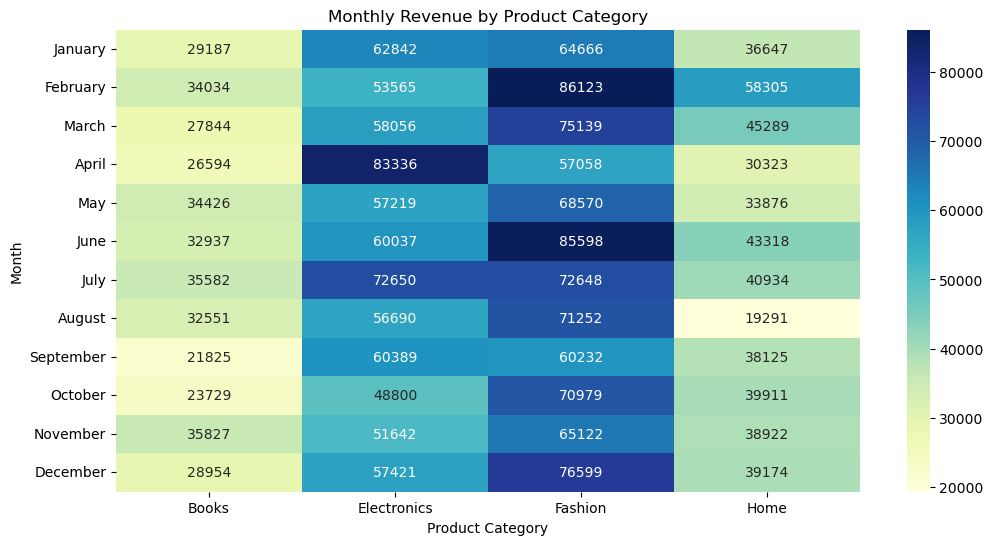

In [15]:
# PIVOT TABLE HEATMAP

plt.figure(figsize=(12, 6))

sns.heatmap(
    pivot_table,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu"
)

plt.title("Monthly Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Month")

plt.show()

In [16]:
customer_spending = orders.groupby("customer_id")["amount"].sum()

customer_spending = customer_spending.sort_values(
    ascending=False
)

print("TOP 10 CUSTOMERS")
print(customer_spending.head(10).round(2))

TOP 10 CUSTOMERS
customer_id
226    18140.15
51     18126.28
53     17994.36
131    17639.25
185    17222.49
282    17161.00
121    16564.87
98     15351.48
255    15313.47
136    15265.80
Name: amount, dtype: float64


In [17]:
total_customers = len(customer_spending)

top_10_count = max(1, int(total_customers * 0.10))

top_10_revenue = customer_spending.head(top_10_count).sum()

total_revenue = customer_spending.sum()

top_10_percentage = (top_10_revenue / total_revenue) * 100

print("Total customers:", total_customers)
print("Top 10% customers:", top_10_count)
print("Total revenue:", round(total_revenue, 2))
print("Revenue from top 10%:", round(top_10_revenue, 2))
print("Top 10% revenue contribution:", round(top_10_percentage, 2), "%")

Total customers: 300
Top 10% customers: 30
Total revenue: 2404233.29
Revenue from top 10%: 455331.97
Top 10% revenue contribution: 18.94 %


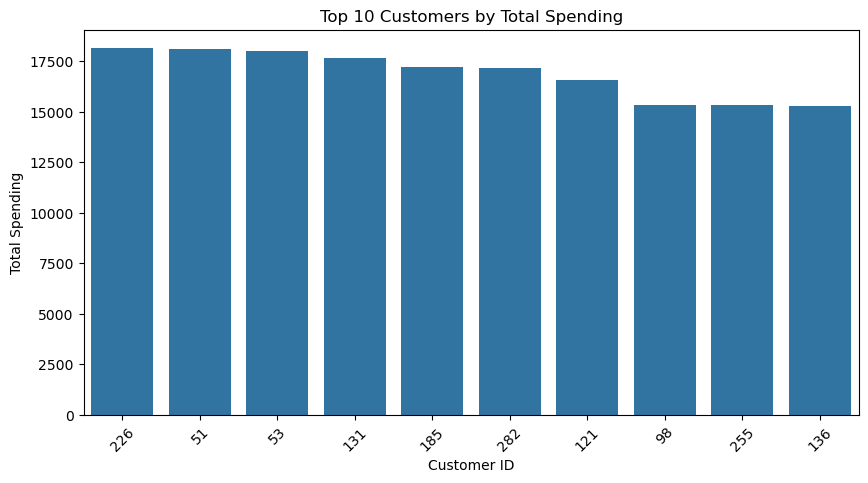

In [18]:
top_customers = customer_spending.head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_customers.index.astype(str),
    y=top_customers.values
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)

plt.show()


In [19]:
print("BUSINESS ANALYSIS SUMMARY")

print("\n1. Best Sales Month:")
print(monthly_sales.idxmax())

print("\n2. Lowest Sales Month:")
print(monthly_sales.idxmin())

print("\n3. Best Product Category:")
print(category_sales["sum"].idxmax())

print("\n4. Lowest Product Category:")
print(category_sales["sum"].idxmin())

print("\n5. Top 10% Customer Revenue Contribution:")
print(round(top_10_percentage, 2), "%")

BUSINESS ANALYSIS SUMMARY

1. Best Sales Month:
February

2. Lowest Sales Month:
August

3. Best Product Category:
Fashion

4. Lowest Product Category:
Books

5. Top 10% Customer Revenue Contribution:
18.94 %


## Business Recommendations

1. **Improve Low-Sales Months:** 
   Offer discounts and special promotions during months with lower revenue.

2. **Focus on Best-Selling Categories:** 
   Maintain sufficient stock and promote products from the highest-revenue category.

3. **Reward Valuable Customers:** 
   Provide loyalty points and special offers to high-spending customers.

4. **Improve Low-Performing Categories:** 
   Study customer preferences and improve marketing for categories with lower revenue.

# Project Conclusion

In this project, I performed an end-to-end sales analysis using Python.

I used Pandas, NumPy, Matplotlib, and Seaborn to analyze the e-commerce sales dataset.

The main tasks completed were:

1. Created and explored the sales dataset.
2. Checked missing values and duplicate records.
3. Extracted month, weekday, and quarter from dates.
4. Analyzed monthly revenue and sales growth.
5. Compared sales across product categories.
6. Created a monthly sales pivot table and heatmap.
7. Identified the highest-spending customers.
8. Calculated the revenue contribution of the top 10% customers.
9. Created visualizations and business recommendations.

The analysis helped identify sales trends, popular product categories, and valuable customers.

This project improved my practical understanding of data analysis and visualization using Python.